# 07 - What regularization changed in my dataset

**Learning goal:** derive Ridge/Lasso/ElasticNet objectives, then inspect
the *saved training-CV evidence* rather than run another search.
There are no final-test comparisons in this lesson. All curves below read
[cv_results.csv](../reports/metrics/final_experiment/cv_results.csv).

Coefficient paths and Lasso nonzero-count paths were not saved. The only
available coefficient vector is the packaged full-data Ridge refit at the
locked alpha. We will show that vector and explicitly preserve the gaps.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split
from ecommerce_customer_value_prediction.models.predict import load_model

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "reports" / "metrics" / "final_experiment").is_dir(), "Run from repo root or notebooks/"
EXPERIMENT = ROOT / "reports" / "metrics" / "final_experiment"

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

protected = [
    path for directory in (EXPERIMENT, ROOT / "models")
    for path in directory.rglob("*") if path.is_file()
]
initial_hashes = {str(path): sha256(path) for path in protected}

# This is an artifact-reading lesson, not another modeling experiment.
def forbid_fit(*args, **kwargs):
    raise RuntimeError("Fitting/tuning is forbidden in this completed-experiment lesson.")

for cls in (Pipeline, LinearRegression, Ridge, Lasso, ElasticNet,
            StandardScaler, OneHotEncoder, GridSearchCV, RandomizedSearchCV):
    cls.fit = forbid_fit

def read_json(name):
    return json.loads((EXPERIMENT / name).read_text(encoding="utf-8"))

lock = read_json("selection.json")
test_report = read_json("test_metrics.json")
errors = read_json("error_analysis.json")
metadata = json.loads((ROOT / "models" / "model_metadata.json").read_text(encoding="utf-8"))
cv_grid = pd.read_csv(EXPERIMENT / "cv_results.csv")
assert sha256(EXPERIMENT / "selection.json") == test_report["selection_sha256"]
assert metadata["selection_sha256"] == test_report["selection_sha256"]
assert lock["selected_model"] == metadata["model_type"] == errors["model"]
assert metadata["final_test_metrics"] == test_report["models"][lock["selected_model"]]
assert pd.Timestamp(lock["locked_at"]) < pd.Timestamp(test_report["evaluated_at"])
winner = lock["selected_model"]
candidates = lock["candidates"]
cv_summary = pd.DataFrame({
    name: candidate["cv_metrics"] for name, candidate in candidates.items()
}).T
cv_metric_columns = [
    "mean_cv_rmse_log", "std_cv_rmse_log", "mean_cv_mae_log",
    "std_cv_mae_log", "mean_cv_r2_log", "std_cv_r2_log"
]
cv_summary[cv_metric_columns] = cv_summary[cv_metric_columns].astype(float)
test_summary = pd.DataFrame(test_report["models"]).T
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 6)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True})

def cv_curve(model, ax):
    points = cv_grid.loc[cv_grid["model"].eq(model)].sort_values("alpha")
    ax.errorbar(points["alpha"], points["mean_cv_rmse_log"],
                yerr=points["std_cv_rmse_log"], fmt="o-", capsize=3,
                label="Saved CV mean +/- fold SD (not a confidence interval)")
    chosen_alpha = candidates[model]["hyperparameters"]["alpha"]
    ax.axvline(chosen_alpha, color="crimson", linestyle="--", label=f"Locked alpha={chosen_alpha:g}")
    ax.set(xscale="log", xlabel="alpha (log axis)", ylabel="CV RMSE, log1p target",
           title=f"{model}: saved training-only CV evidence")
    ax.legend(fontsize=8)

def ridge_coefficients():
    pipeline = load_model(ROOT / "models" / "customer_value_model.joblib")
    preprocessor = pipeline.named_steps["preprocessor"]
    coefficients = pipeline.named_steps["regressor"].coef_
    table = pd.DataFrame({
        "encoded_feature": preprocessor.get_feature_names_out(),
        "coefficient": coefficients,
        "absolute_coefficient": np.abs(coefficients),
    })
    return pipeline, table

print("Source: completed experiment artifacts; fit/tuning calls are blocked.")
print("Winner:", winner, "| hyperparameters:", candidates[winner]["hyperparameters"])
print("Locked at:", lock["locked_at"], "| evaluated at:", test_report["evaluated_at"])
print("Protected files:", len(protected), "| no test predictions are recomputed.")

2026-10-11 00:38:08.195 | INFO     | ecommerce_customer_value_prediction.config.settings:<module>:33 - PROJ_ROOT: C:\Masters_AIDSE_IIT\AI_Code\ecommerce-customer-value-prediction


Source: completed experiment artifacts; fit/tuning calls are blocked.
Winner: ridge | hyperparameters: {'alpha': 10.0, 'copy_X': True, 'fit_intercept': True, 'max_iter': None, 'positive': False, 'random_state': None, 'solver': 'auto', 'tol': 0.0001}
Locked at: 2026-10-10T18:40:42.345137+00:00 | evaluated at: 2026-10-10T18:40:42.385874+00:00
Protected files: 8 | no test predictions are recomputed.


## 1. Ridge: least squares plus a preference for smaller coefficients

OLS minimizes squared residuals \( \|y-\beta_0-Z\beta\|_2^2 \).
Ridge adds a squared-coefficient penalty:
\[
\min_{\beta_0,\beta}
\underbrace{\sum_i(y_i-\beta_0-z_i^\mathsf{T}\beta)^2}_{\text{fit the target}}
+\underbrace{\alpha\sum_j\beta_j^2}_{\text{L2 penalty}}.
\]
The intercept is not penalized. A coefficient twice as large costs four
times as much penalty. The optimization balances fit against coefficient
magnitude; it does not directly minimize business revenue error.

**alpha** controls that tradeoff. At alpha=0 the objective reduces to OLS;
increasing alpha generally reduces the coefficient vector's norm.
Ridge does not generally force coefficients to exactly zero.

For centered, full-rank algebra, Ridge has the form
\((Z^\mathsf{T}Z+\alpha I)^{-1}Z^\mathsf{T}y\).
The added diagonal helps stabilize poorly determined directions in a
correlated design. In an SVD, its direction-wise shrinkage factors are
\(d_k^2/(d_k^2+\alpha)\): small-singular-value directions shrink most.
This is a conceptual derivation, not a new fit.

## 2. Why was Ridge alpha=10 selected?

The existing grid tested alpha from \(10^{-4}\) through \(10^4\).
All candidates used the complete pipeline and the same training folds.
The lowest **mean CV RMSE on the log target** won. `rank` in the saved CSV
is within each family's search, not a ranking across families.
Error bars below show fold standard deviation, not significance or confidence.

,model,mean_cv_rmse_log,std_cv_rmse_log,rank,alpha,l1_ratio
8,ridge,1.728910,0.073463,8,0.0001,NaN
7,ridge,1.728905,0.073461,7,0.0010,NaN
6,ridge,1.728857,0.073447,6,0.0100,NaN
4,ridge,1.728428,0.073306,4,0.1000,NaN
2,ridge,1.726409,0.072254,2,1.0000,NaN
1,ridge,1.725261,0.070007,1,10.0000,NaN
3,ridge,1.726597,0.067750,3,100.0000,NaN
5,ridge,1.728522,0.059165,5,1000.0000,NaN
9,ridge,1.816984,0.039761,9,10000.0000,NaN


Locked alpha: 10.0
Saved best CV RMSE: 1.7252608564270908


,mean_cv_rmse_log,std_cv_rmse_log,mean_cv_mae_log,std_cv_mae_log,mean_cv_r2_log,std_cv_r2_log
ridge,1.725261,0.070007,1.399844,0.052029,0.251098,0.051559


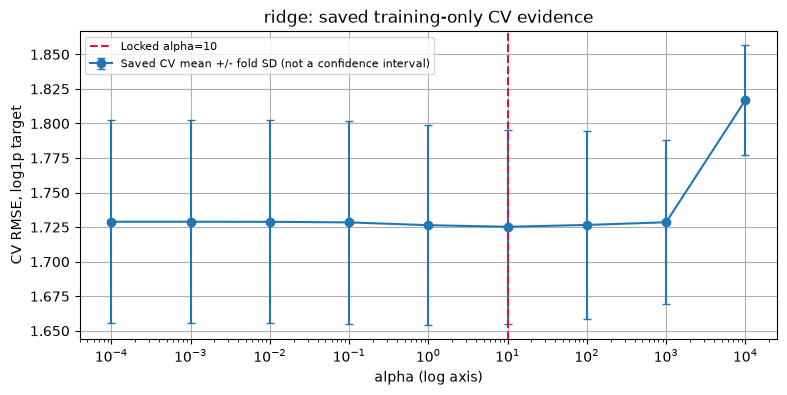

In [2]:
ridge_grid = cv_grid.loc[cv_grid["model"].eq("ridge")].sort_values("alpha")
display(ridge_grid)
best_ridge = ridge_grid.loc[ridge_grid["rank"].eq(1)].iloc[0]
assert best_ridge["alpha"] == candidates["ridge"]["hyperparameters"]["alpha"]
print("Locked alpha:", best_ridge["alpha"])
print("Saved best CV RMSE:", candidates["ridge"]["selection_cv_rmse_log"])
display(cv_summary.loc[["ridge"], cv_metric_columns])
fig, ax = plt.subplots()
cv_curve("ridge", ax)
plt.show()

The optimum is shallow: alpha=10 gives **1.725261**, compared with
**1.726409** at alpha=1 and **1.726597** at alpha=100. Very large alpha=10,000
raises CV RMSE to **1.816984**, consistent with too much shrinkage/underfitting.
The rule chose the minimum; these small differences do not establish that
alpha=10 is uniquely or statistically significantly best.

## 3. Inspecting the actual saved Ridge coefficients

The next table reads the already-fitted joblib pipeline; it never calls fit.
**Scope: full-data refit, 4,374 customers, alpha=10.** These are not the
coefficients of a CV fold or the earlier training-partition holdout model.

A numeric coefficient multiplies a standardized value; country coefficients
multiply binary indicators. Those scales differ, so ranking all encoded
coefficients by magnitude is not a universal feature-importance measure.
Feature correlation and dummy/intercept allocation also affect interpretation.
L2 shrinkage is a vector-level property; do not assume every individual
correlated coefficient moves monotonically across alpha.

2026-10-11 00:38:08.510 | INFO     | ecommerce_customer_value_prediction.models.train:load_model:339 - [load_model] Pipeline loaded from C:\Masters_AIDSE_IIT\AI_Code\ecommerce-customer-value-prediction\models\customer_value_model.joblib
Coefficient scope: 4374 full-data rows
Intercept (unpenalized): 1.3468035843894084


,encoded_feature,coefficient,absolute_coefficient
0,num__recency_days,-0.496356,0.496356
1,num__frequency,0.305177,0.305177
2,num__monetary,0.141111,0.141111
3,num__avg_basket_value,0.073121,0.073121
4,num__unique_products,0.098668,0.098668
5,num__tenure_days,0.293185,0.293185
6,num__purchase_rate,0.037597,0.037597
7,cat__country_Australia,0.049046,0.049046
8,cat__country_Austria,0.195541,0.195541
9,cat__country_Bahrain,-0.164242,0.164242


encoded_coefficients       47.000000
L1_norm                    11.267480
L2_norm                     2.097173
exact_zero_coefficients     0.000000
abs_below_1e-10             0.000000
Name: Saved full-data Ridge coefficient statistics, dtype: float64

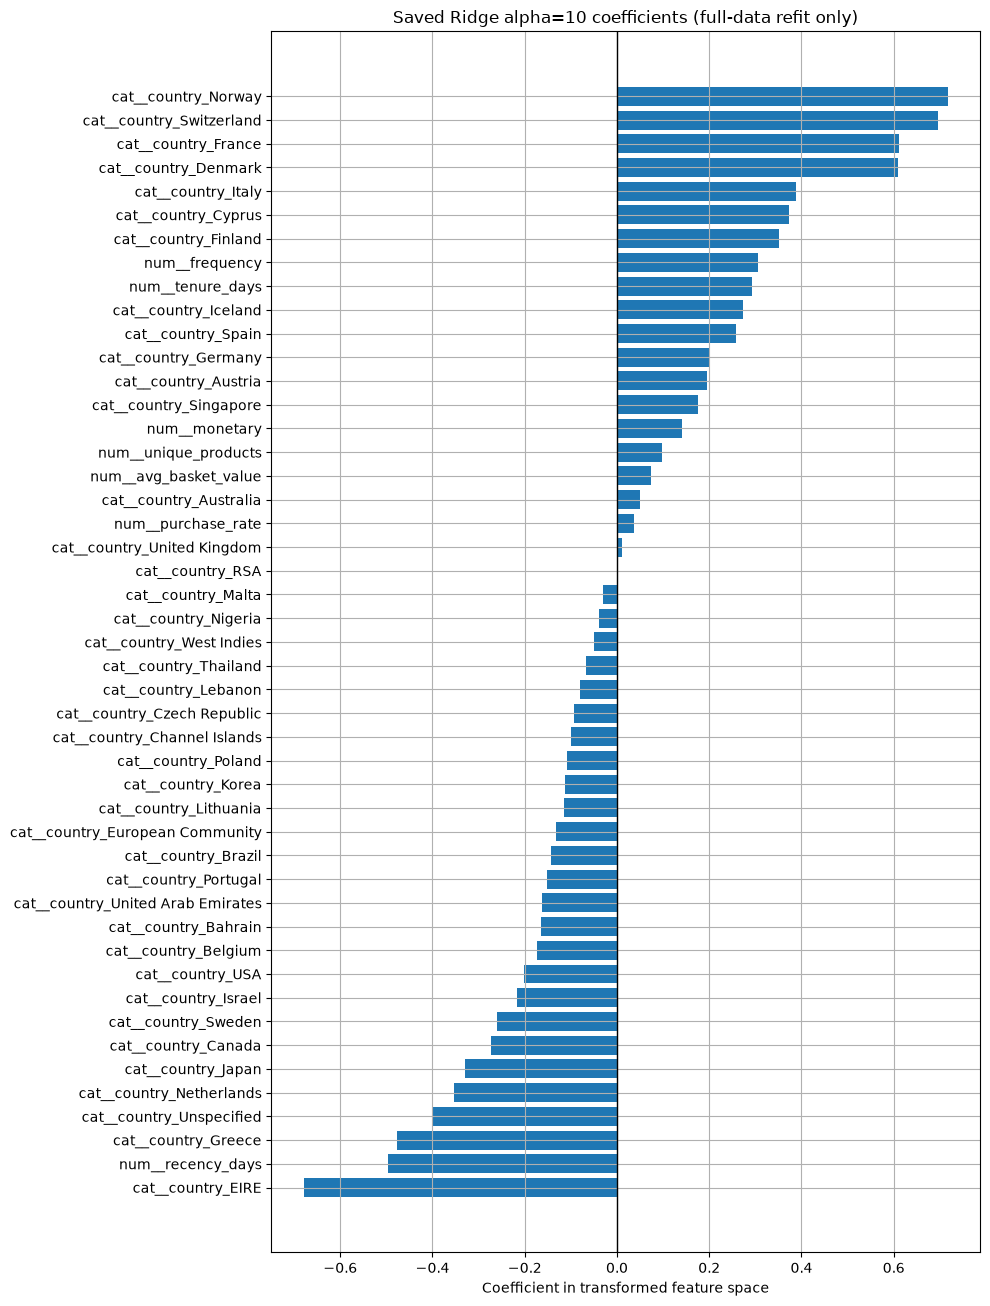

In [3]:
ridge_pipeline, ridge_table = ridge_coefficients()
print("Coefficient scope:", metadata["n_training_customers"], "full-data rows")
print("Intercept (unpenalized):", ridge_pipeline.named_steps["regressor"].intercept_)
display(ridge_table)
display(pd.Series({
    "encoded_coefficients": len(ridge_table),
    "L1_norm": ridge_table["absolute_coefficient"].sum(),
    "L2_norm": np.linalg.norm(ridge_table["coefficient"]),
    "exact_zero_coefficients": int(ridge_table["coefficient"].eq(0).sum()),
    "abs_below_1e-10": int(ridge_table["absolute_coefficient"].lt(1e-10).sum()),
}, name="Saved full-data Ridge coefficient statistics"))
ordered = ridge_table.sort_values("coefficient")
fig, ax = plt.subplots(figsize=(10, max(5, len(ordered) * 0.28)))
ax.barh(ordered["encoded_feature"], ordered["coefficient"])
ax.axvline(0, color="black", linewidth=1)
ax.set(title="Saved Ridge alpha=10 coefficients (full-data refit only)",
       xlabel="Coefficient in transformed feature space")
fig.tight_layout()
plt.show()

**Unavailable:** alpha-versus-coefficient-magnitude trajectories were not
persisted. One coefficient vector at alpha=10 cannot establish a path.
We will not refit other alphas, interpolate invented paths, or label a
theoretical shrinkage formula as empirical results.

## 4. Lasso: why L1 can make a coefficient exactly zero

scikit-learn Lasso minimizes
\[
\frac{1}{2n}\|y-\beta_0-Z\beta\|_2^2+\alpha\sum_j|\beta_j|.
\]
L1 uses absolute magnitude rather than a square. Its corner at zero allows
the optimum to land exactly at zero, yielding **sparsity**. In a normalized
orthogonal example, soft-thresholding maps a small coefficient signal to
zero; with correlated predictors, allocation is more complicated.

A zero coefficient means that variable is unused in that fitted linear
expression; it does not prove the feature is causally irrelevant. Lasso can
choose one of several correlated substitutes. Scaling makes the penalties
comparable across numeric inputs.

**Important normalization detail:** sklearn Ridge uses an unnormalized
residual sum; Lasso and ElasticNet use residual sum divided by \(2n\).
Therefore alpha=10 in Ridge and alpha=0.05 in Lasso are not directly comparable
quantities or statements that one penalty is "200 times stronger."

,model,mean_cv_rmse_log,std_cv_rmse_log,rank,alpha,l1_ratio
13,lasso,1.728371,0.073050,4,0.0001,NaN
12,lasso,1.728047,0.071753,3,0.0005,NaN
16,lasso,1.729179,0.070720,7,0.0010,NaN
15,lasso,1.728736,0.068046,6,0.0050,NaN
14,lasso,1.728561,0.067598,5,0.0100,NaN
10,lasso,1.726086,0.060478,1,0.0500,NaN
11,lasso,1.726516,0.054931,2,0.1000,NaN
17,lasso,1.834313,0.035746,8,0.5000,NaN
18,lasso,1.995065,0.039912,9,1.0000,NaN


,mean_cv_rmse_log,std_cv_rmse_log,mean_cv_mae_log,std_cv_mae_log,mean_cv_r2_log,std_cv_r2_log
lasso,1.726086,0.060478,1.416271,0.045716,0.250547,0.043983


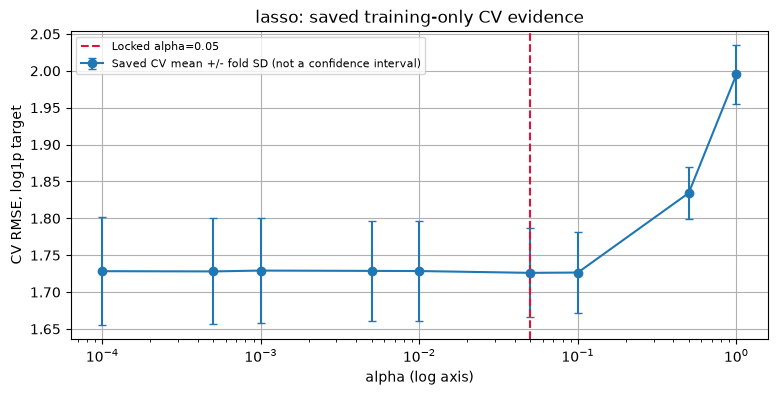

Locked Lasso hyperparameters: {'alpha': 0.05, 'copy_X': True, 'fit_intercept': True, 'max_iter': 10000, 'positive': False, 'precompute': False, 'random_state': None, 'selection': 'cyclic', 'tol': 0.0001, 'warm_start': False}


In [4]:
display(cv_grid.loc[cv_grid["model"].eq("lasso")].sort_values("alpha"))
display(cv_summary.loc[["lasso"], cv_metric_columns])
fig, ax = plt.subplots()
cv_curve("lasso", ax)
plt.show()
print("Locked Lasso hyperparameters:", candidates["lasso"]["hyperparameters"])

Lasso's locked alpha=**0.05** has CV RMSE **1.726086 +/- 0.060478**.
The saved curve is not strictly monotonic. At alpha=0.5 and 1.0, RMSE worsens
to **1.834313** and **1.995065**: evidence consistent with excessive penalty
removing useful signal. The scores alone do **not** prove all coefficients
became zero at those alphas.

**Lasso alpha-versus-nonzero-count plot:** not recoverable. The original
search saved validation scores, not coefficient vectors or counts per alpha.
The fitted Lasso pipeline itself was not persisted. We know how L1 permits
sparsity, but cannot state how many coefficients this experiment zeroed.

## 5. ElasticNet: combine sparsity and stability

With \(\rho=\texttt{l1_ratio}\), scikit-learn uses
\[
\frac{1}{2n}\|y-\beta_0-Z\beta\|_2^2
+\alpha\rho\|\beta\|_1
+\frac{\alpha(1-\rho)}{2}\|\beta\|_2^2.
\]
**alpha** controls overall regularization; **l1_ratio** controls the L1/L2
mix. At rho=1 it is Lasso; rho=0 is an L2-only normalized objective,
not numerically the same alpha as sklearn Ridge.
The saved grid excludes endpoints to avoid duplicating families.

The L1 part can zero coefficients; the L2 part can stabilize correlated
directions. It need not preserve every correlated feature, and actual
sparsity was not recorded here.

,model,mean_cv_rmse_log,std_cv_rmse_log,rank,alpha,l1_ratio
28,elasticnet,1.727820,0.073056,10,0.0001,0.10
29,elasticnet,1.727892,0.073074,11,0.0001,0.25
32,elasticnet,1.728069,0.073051,14,0.0001,0.50
34,elasticnet,1.728221,0.073041,16,0.0001,0.75
35,elasticnet,1.728302,0.073042,17,0.0001,0.90
21,elasticnet,1.725641,0.071195,3,0.0010,0.10
23,elasticnet,1.726077,0.071099,5,0.0010,0.25
26,elasticnet,1.727075,0.070848,8,0.0010,0.50
30,elasticnet,1.727952,0.070660,12,0.0010,0.75
38,elasticnet,1.728617,0.070701,20,0.0010,0.90


,mean_cv_rmse_log,std_cv_rmse_log,mean_cv_mae_log,std_cv_mae_log,mean_cv_r2_log,std_cv_r2_log
elasticnet,1.72548,0.056377,1.425673,0.042814,0.251124,0.040871


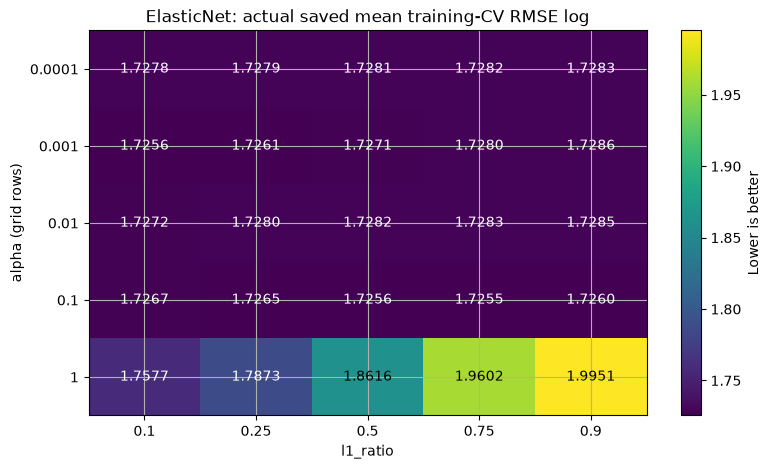

Locked alpha/l1_ratio: 0.1 0.75


In [5]:
en_grid = cv_grid.loc[cv_grid["model"].eq("elasticnet")].copy()
display(en_grid.sort_values(["alpha", "l1_ratio"]))
display(cv_summary.loc[["elasticnet"], cv_metric_columns])
heatmap = en_grid.pivot(index="alpha", columns="l1_ratio", values="mean_cv_rmse_log")
fig, ax = plt.subplots(figsize=(9, 5))
image = ax.imshow(heatmap, aspect="auto", cmap="viridis")
ax.set_xticks(range(len(heatmap.columns)), [f"{x:g}" for x in heatmap.columns])
ax.set_yticks(range(len(heatmap.index)), [f"{x:g}" for x in heatmap.index])
for row in range(len(heatmap.index)):
    for col in range(len(heatmap.columns)):
        ax.text(col, row, f"{heatmap.iloc[row, col]:.4f}", ha="center", va="center",
                color="white" if heatmap.iloc[row, col] < 1.85 else "black")
ax.set(xlabel="l1_ratio", ylabel="alpha (grid rows)",
       title="ElasticNet: actual saved mean training-CV RMSE log")
fig.colorbar(image, ax=ax, label="Lower is better")
plt.show()
print("Locked alpha/l1_ratio:", candidates["elasticnet"]["hyperparameters"]["alpha"],
      candidates["elasticnet"]["hyperparameters"]["l1_ratio"])

The locked mixture is **alpha=0.1, l1_ratio=0.75**, with CV RMSE
**1.725480 +/- 0.056377**. That is slightly above Ridge's minimum.
At alpha=1 and rho=0.9, saved RMSE is **1.995065**, illustrating the risk
of excessive regularization rather than a guarantee of useful sparsity.

## 6. All four models: development evidence only

The next table and plot use the saved CV means and fold standard deviations.
Hyperparameter search selected the best candidate per family; the overall
rule compared family minima. The final test had no role in either decision.
With multiple search candidates, these CV minima may be optimistic estimates;
they are not independent final generalization measurements.

,mean_cv_rmse_log,std_cv_rmse_log,mean_cv_mae_log,std_cv_mae_log,mean_cv_r2_log,std_cv_r2_log,RMSE_reduction_vs_OLS,RMSE_reduction_percent
ridge,1.725261,0.070007,1.399844,0.052029,0.251098,0.051559,0.003650,0.211116
elasticnet,1.725480,0.056377,1.425673,0.042814,0.251124,0.040871,0.003431,0.198449
lasso,1.726086,0.060478,1.416271,0.045716,0.250547,0.043983,0.002825,0.163398
linear,1.728911,0.073463,1.398178,0.055911,0.247781,0.055083,0.000000,0.000000


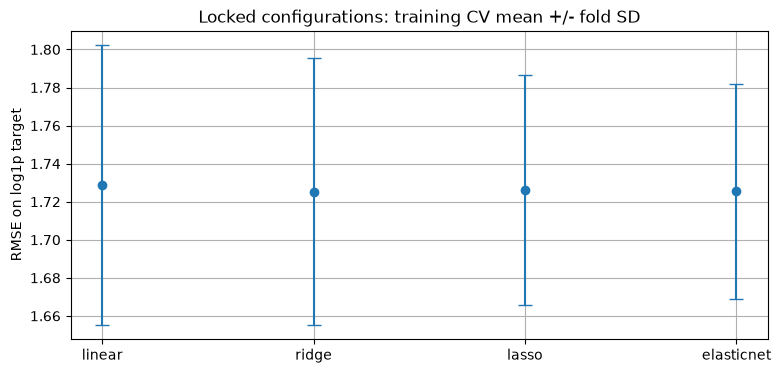

ridge: RMSE reduction=0.003650 (0.211%)
lasso: RMSE reduction=0.002825 (0.163%)
elasticnet: RMSE reduction=0.003431 (0.198%)


In [6]:
comparison = cv_summary[cv_metric_columns].copy()
baseline_rmse = comparison.loc["linear", "mean_cv_rmse_log"]
comparison["RMSE_reduction_vs_OLS"] = baseline_rmse - comparison["mean_cv_rmse_log"]
comparison["RMSE_reduction_percent"] = 100 * comparison["RMSE_reduction_vs_OLS"] / baseline_rmse
display(comparison.sort_values("mean_cv_rmse_log"))
fig, ax = plt.subplots()
ax.errorbar(comparison.index, comparison["mean_cv_rmse_log"],
            yerr=comparison["std_cv_rmse_log"], fmt="o", capsize=5)
ax.set(title="Locked configurations: training CV mean +/- fold SD",
       ylabel="RMSE on log1p target")
plt.show()
for name in ("ridge", "lasso", "elasticnet"):
    print(f"{name}: RMSE reduction={comparison.loc[name, 'RMSE_reduction_vs_OLS']:.6f}"
          f" ({comparison.loc[name, 'RMSE_reduction_percent']:.3f}%)")

## 7. What did regularization actually change in MY dataset?

- **Predictive change is small in development:** OLS RMSE 1.728911 becomes
  Ridge 1.725261, a reduction of about **0.003650 (0.211%)**.
  Lasso and ElasticNet improve RMSE only slightly too. Fold SDs around
  0.056-0.073 are far larger than family-mean differences.
- **Not every metric improves:** Ridge CV MAE is slightly above OLS MAE;
  Lasso/ElasticNet MAE also increases, while RMSE slightly decreases.
  Selection optimized RMSE, not all metrics simultaneously.
- **Fold variability shrinks descriptively:** Ridge RMSE SD is 0.070007,
  Lasso 0.060478, ElasticNet 0.056377 versus OLS 0.073463.
  This does not establish coefficient stability or a significant variance
  reduction: bootstrap coefficients and paired fold results were not saved.
- **Mechanism:** penalties discourage large coefficients in correlated
  feature directions; L1 additionally permits sparsity. Actual OLS-to-Ridge
  shrinkage and Lasso sparsity counts cannot be measured from the available
  coefficient artifacts. The displayed Ridge vector is only one full-data fit.
- **Too much penalty hurts:** the saved high-alpha scores rise markedly.
  This is consistent with underfitting: bias can increase when useful signal
  is suppressed. We did not directly estimate bias or variance components.
- **Bias-variance tradeoff:** restricting coefficients can sacrifice fit
  (more bias) to reduce sensitivity (less variance). CV assesses the combined
  effect on held-out folds; it does not separately measure those components.

**Answer:** regularization changed the optimization and slightly improved
CV log RMSE, but it did not transform this dataset into an accurate
business-revenue forecasting problem. Ridge remained the minimum-CV choice;
we have no basis to claim dramatic superiority, measured coefficient
stability, or a recorded Lasso feature-selection result.

In [7]:
display(pd.DataFrame([
    ["Ridge alpha vs CV RMSE", "Available: saved search scores"],
    ["Ridge alpha vs coefficient magnitude", "Unavailable: path not saved"],
    ["Lasso alpha vs CV RMSE", "Available: saved search scores"],
    ["Lasso alpha vs nonzero count", "Unavailable: coefficients/counts not saved"],
    ["ElasticNet alpha / l1_ratio CV surface", "Available: saved search scores"],
    ["Cross-model coefficient statistics", "Only full-data Ridge coefficients available"],
], columns=["Evidence requested", "Evidence actually available"]))

,Evidence requested,Evidence actually available
0,Ridge alpha vs CV RMSE,Available: saved search scores
1,Ridge alpha vs coefficient magnitude,Unavailable: path not saved
2,Lasso alpha vs CV RMSE,Available: saved search scores
3,Lasso alpha vs nonzero count,Unavailable: coefficients/counts not saved
4,ElasticNet alpha / l1_ratio CV surface,Available: saved search scores
5,Cross-model coefficient statistics,Only full-data Ridge coefficients available


In [8]:
for filename, original in initial_hashes.items():
    assert sha256(Path(filename)) == original, f"Artifact changed: {filename}"
current_files = {
    str(path) for directory in (EXPERIMENT, ROOT / "models")
    for path in directory.rglob("*") if path.is_file()
}
assert current_files == set(initial_hashes), "Protected artifact inventory changed."
assert Pipeline.fit is forbid_fit and GridSearchCV.fit is forbid_fit
print("PASS: no fitting/tuning; experiment and model artifact bytes/inventory unchanged.")

PASS: no fitting/tuning; experiment and model artifact bytes/inventory unchanged.
